In [1]:
import sys
sys.path.insert(0, "..")   # project root, so `src` can be imported

import time                        # timing training and prediction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch: tensors, neural network layers, optimizers
import torch
import torch.nn as nn
import torch.optim as optim

# Evaluation
from sklearn.metrics import classification_report, confusion_matrix

from src.data import get_dataloaders, SEED

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


def predict(model, loader):
    """Predicted digits and true labels for every image in the loader."""
    model.eval()                     # evaluation mode
    preds, labels = [], []
    with torch.no_grad():            # no gradients needed for inference: faster, less memory
        for images, y in loader:
            outputs = model(images.to(device))
            preds.append(outputs.argmax(1).cpu())   # index of the highest score = predicted digit
            labels.append(y)
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()


def accuracy(model, loader):
    pred, true = predict(model, loader)
    return (pred == true).mean()


def evaluate_model(make_model, name, epochs=5, lr=0.001):
    """Train a fresh model, print validation accuracy and timings like 02_classical_ML.

    make_model is the class (e.g. CNNModel), so the model is created after seeding:
    every run starts from the same weights and sees the batches in the same order.
    """
    torch.manual_seed(SEED)
    model = make_model().to(device)
    criterion = nn.CrossEntropyLoss()                     # standard loss for multi-class classification
    optimizer = optim.Adam(model.parameters(), lr=lr)     # updates the model weights
    history = {"train_loss": [], "val_acc": []}

    train_time = 0.0   # training only; the per-epoch validation check is not counted
    for epoch in range(epochs):
        start = time.perf_counter()
        model.train()                          # training mode
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()              # clear gradients from the previous batch
            loss = criterion(model(images), labels)
            loss.backward()                    # backpropagation: compute gradients
            optimizer.step()                   # update weights
            running_loss += loss.item()
        train_time += time.perf_counter() - start

        history["train_loss"].append(running_loss / len(train_loader))   # mean loss over the epoch's batches
        history["val_acc"].append(accuracy(model, val_loader))
        print(f"  epoch {epoch + 1}/{epochs}: train loss {history['train_loss'][-1]:.4f} | "
              f"val acc {history['val_acc'][-1]:.3f}")

    start = time.perf_counter()
    val_pred, val_true = predict(model, val_loader)
    pred_time = time.perf_counter() - start

    val_acc = (val_pred == val_true).mean()
    print(f"{name}: val acc {val_acc:.3f} | train {train_time:.1f}s | "
          f"predict {pred_time * 1000:.1f} ms ({pred_time / len(val_true) * 1000:.4f} ms/image)")
    result = {"model": name, "val_acc": val_acc, "train_time": train_time, "pred_time": pred_time}
    return model, history, result


def plot_history(history, title):
    """Training loss and validation accuracy per epoch."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
    ax1.plot(epochs, history["train_loss"], marker="o")
    ax1.set_title("Training loss"); ax1.set_xlabel("Epoch"); ax1.grid(True)
    ax2.plot(epochs, history["val_acc"], marker="o")
    ax2.set_title("Validation accuracy"); ax2.set_xlabel("Epoch"); ax2.grid(True)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


results = []   # one row per chosen model, shown as a table at the end

Device: cuda


In [3]:
# Same 55k / 5k split as the classical models; images are normalized with MNIST's mean and std
train_loader, val_loader, test_loader = get_dataloaders()   # test_loader is not used here

print(len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))   # 55000 5000 10000
images, labels = next(iter(train_loader))
print(images.shape, labels.shape)   # torch.Size([64, 1, 28, 28]) torch.Size([64])

55000 5000 10000
torch.Size([64, 1, 28, 28]) torch.Size([64])


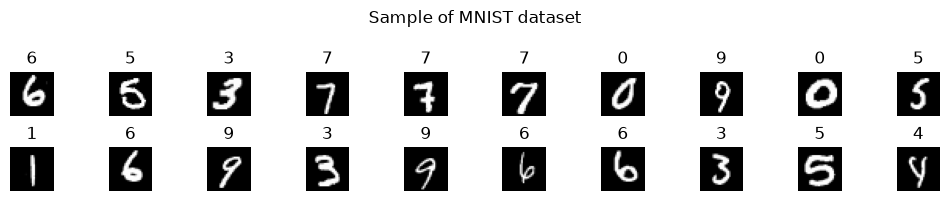

In [4]:
# Plot the first n images of the dataset in a 2-row grid, each titled with its label
def show_sample(dataset, n=20):
    plt.figure(figsize=(10, 2))
    for i in range(n):
        image, label = dataset[i]
        plt.subplot(2, n//2, i+1)
        plt.imshow(image.squeeze(), cmap='gray')   # squeeze: [1, 28, 28] -> [28, 28] for imshow
        plt.title(label)
        plt.axis('off')
    plt.suptitle("Sample of MNIST dataset", fontsize = 12)
    plt.tight_layout()
    plt.show()

show_sample(train_loader.dataset)

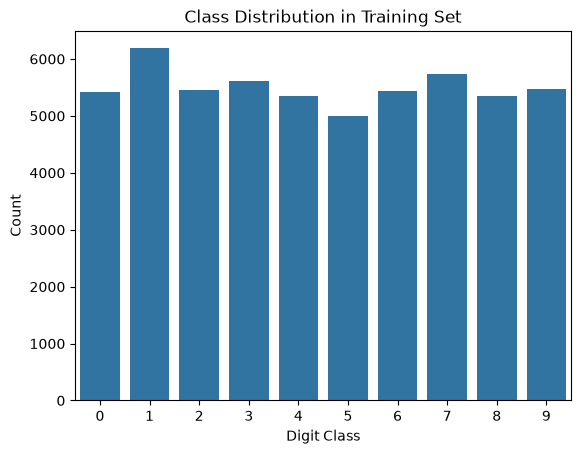

In [5]:
# Checking Class Distribution
# (a roughly equal count per digit means the dataset is balanced)

train_subset = train_loader.dataset   # Subset of the 60k training set
labels = train_subset.dataset.targets[train_subset.indices].numpy()   # read labels directly, no image transforms

sns.countplot(x=labels)
plt.title("Class Distribution in Training Set")
plt.xlabel("Digit Class")
plt.ylabel("Count")
plt.show()

In [6]:
# Small CNN: two conv + pool blocks extract features, two fully connected layers classify them
class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)     # 1 input channel (grayscale) -> 16 feature maps, 3x3 kernel
        self.pool = nn.MaxPool2d(2, 2)                  # halves height and width
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)    # 16 -> 32 feature maps
        self.fc1 = nn.Linear(32 * 7 * 7, 128)           # 28x28 pooled twice -> 7x7, with 32 channels
        self.fc2 = nn.Linear(128, 10)                   # one output score (logit) per digit

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))   # [B, 1, 28, 28] -> [B, 16, 14, 14]
        x = self.pool(torch.relu(self.conv2(x)))   # -> [B, 32, 7, 7]
        x = x.flatten(1)                           # flatten to [B, 1568]
        x = torch.relu(self.fc1(x))
        return self.fc2(x)                         # raw logits; softmax is applied inside the loss

  epoch 1/5: train loss 0.1795 | val acc 0.973
  epoch 2/5: train loss 0.0555 | val acc 0.986
  epoch 3/5: train loss 0.0373 | val acc 0.988
  epoch 4/5: train loss 0.0286 | val acc 0.989
  epoch 5/5: train loss 0.0214 | val acc 0.986
CNN (5 epochs): val acc 0.986 | train 32.7s | predict 553.8 ms (0.1108 ms/image)
Training set score: 0.993


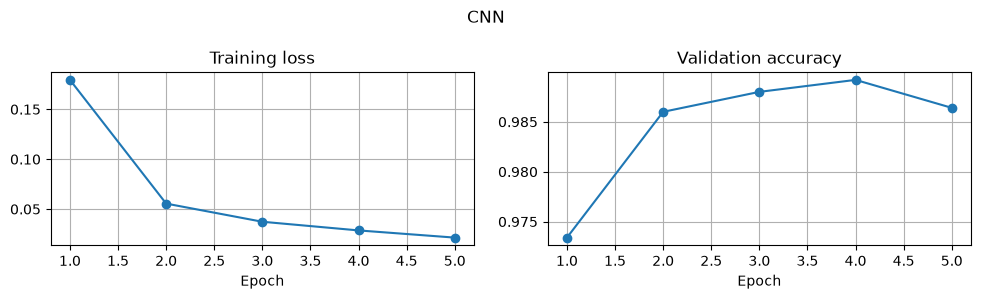

In [7]:
cnn, cnn_history, cnn_result = evaluate_model(CNNModel, "CNN (5 epochs)")

print("Training set score: {:.3f}".format(accuracy(cnn, train_loader)))
plot_history(cnn_history, "CNN")

  epoch 1/5: train loss 0.1948 | val acc 0.983
  epoch 2/5: train loss 0.0826 | val acc 0.986
  epoch 3/5: train loss 0.0634 | val acc 0.986
  epoch 4/5: train loss 0.0537 | val acc 0.987
  epoch 5/5: train loss 0.0474 | val acc 0.988
CNN + BatchNorm + Dropout (5 epochs): val acc 0.988 | train 34.3s | predict 417.6 ms (0.0835 ms/image)
Training set score: 0.993


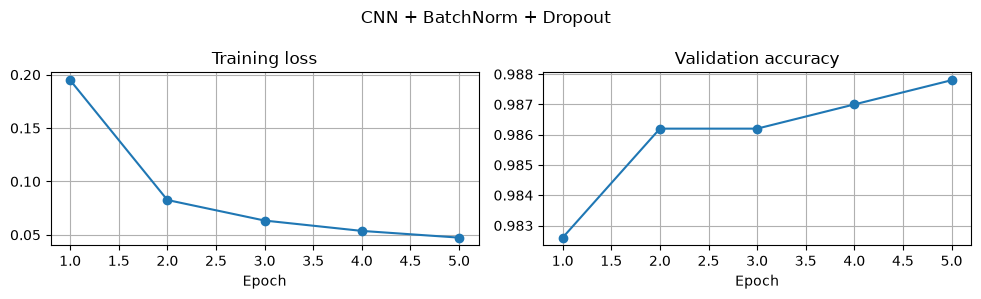

In [8]:
# Same CNN with BatchNorm after each conv (stabilizes and speeds up training)
# and Dropout before the classifier (regularization against overfitting)
class CNNBNDropout(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.25)                 # zeroes 25% of the features during training only
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.bn1(self.conv1(x))))
        x = self.pool(torch.relu(self.bn2(self.conv2(x))))
        x = self.dropout(x.flatten(1))
        x = self.dropout(torch.relu(self.fc1(x)))
        return self.fc2(x)


cnn_bn, cnn_bn_history, cnn_bn_result = evaluate_model(CNNBNDropout, "CNN + BatchNorm + Dropout (5 epochs)")

print("Training set score: {:.3f}".format(accuracy(cnn_bn, train_loader)))
plot_history(cnn_bn_history, "CNN + BatchNorm + Dropout")

In [9]:
for lr in [0.01, 0.001, 0.0001]:
    evaluate_model(CNNModel, f"CNN (5 epochs, lr={lr})", lr=lr)

  epoch 1/5: train loss 0.1984 | val acc 0.962
  epoch 2/5: train loss 0.0991 | val acc 0.975
  epoch 3/5: train loss 0.0889 | val acc 0.974
  epoch 4/5: train loss 0.0808 | val acc 0.973
  epoch 5/5: train loss 0.0781 | val acc 0.974
CNN (5 epochs, lr=0.01): val acc 0.974 | train 33.5s | predict 570.4 ms (0.1141 ms/image)
  epoch 1/5: train loss 0.1793 | val acc 0.973
  epoch 2/5: train loss 0.0554 | val acc 0.986
  epoch 3/5: train loss 0.0371 | val acc 0.988
  epoch 4/5: train loss 0.0291 | val acc 0.989
  epoch 5/5: train loss 0.0216 | val acc 0.989
CNN (5 epochs, lr=0.001): val acc 0.989 | train 33.5s | predict 590.4 ms (0.1181 ms/image)
  epoch 1/5: train loss 0.5250 | val acc 0.930
  epoch 2/5: train loss 0.1576 | val acc 0.959
  epoch 3/5: train loss 0.1045 | val acc 0.968
  epoch 4/5: train loss 0.0802 | val acc 0.976
  epoch 5/5: train loss 0.0665 | val acc 0.977
CNN (5 epochs, lr=0.0001): val acc 0.977 | train 37.5s | predict 438.2 ms (0.0876 ms/image)


### CNN: comparison

| Model | BatchNorm + Dropout | lr | Epochs | Training time | Prediction time (5k images) | Train acc | Val acc | Notes |
|---|---|---|---|---|---|---|---|---|
| `cnn` | No | 0.001 | 5 | 32.7s | 0.55s | 0.993 | 0.986 | Baseline (the notebook's original model); 0.989 at epoch 4 |
| lr loop | No | 0.001 | 5 | 33.5s | 0.59s | – | 0.989 | Same settings and seed as `cnn`, 0.003 apart: GPU training isn't fully deterministic |
| lr loop | No | 0.01 | 5 | 33.5s | 0.57s | – | 0.974 | Too large: loss stalls around 0.08, val acc flat from epoch 2 |
| lr loop | No | 0.0001 | 5 | 37.5s | 0.44s | – | 0.977 | Too small: still improving after 5 epochs, converges too slowly |
| `cnn_bn` | Yes | 0.001 | 5 | 34.3s | 0.42s | 0.993 | 0.988 | Faster start (0.983 after epoch 1 vs 0.973), smoother curve |

- **lr=0.001 (Adam's default) is clearly the best learning rate.** 0.01 overshoots and 0.0001 is too slow for 5 epochs; both lose 1+ point.
- **Run-to-run noise is about ±0.3 points.** The baseline gave 0.986 and 0.989 in two identical runs, because some GPU (cuDNN) operations
  aren't deterministic even with a fixed seed. That's 15 images out of 5,000, larger than the ±0.2% validation standard error.
- **BatchNorm + Dropout doesn't clearly help here.** 0.988 lies between the two baseline runs, and the train accuracy is the same (0.993).
  It learns faster in the first epoch, but after 5 epochs the small CNN on MNIST barely overfits, so there's little for Dropout to fix.
- **Training and prediction times are dominated by data loading**, not the network: each image is converted from PIL to a tensor on every pass.
  So they can't be compared directly with the classical models, which work on arrays already in memory.

**Choice:** the baseline `CNNModel` with lr=0.001 and 5 epochs, about 98.6–98.9% validation accuracy. The BatchNorm + Dropout variant is within noise,
so the simpler model is kept, the same rule as in 02_classical_ML.

In [10]:
# Set to the chosen model after the comparison above
chosen, chosen_result = cnn, cnn_result

results.append(chosen_result)   # chosen CNN

In [11]:
# Comparison of the chosen models (validation set)
pd.DataFrame(results).sort_values("val_acc", ascending=False).round(3)

,model,val_acc,train_time,pred_time
0,CNN (5 epochs),0.986,32.734,0.554


## Summary (validation set)

Same 5k validation images as in 02_classical_ML, so the numbers can be compared directly:

| Model | Settings | Val acc | Training time | Prediction time (5k images) |
|---|---|---|---|---|
| **CNN** | 2 conv + 2 FC, Adam lr=0.001, 5 epochs | **0.986** (0.989 in a repeat run) | 32.7s (GPU) | 0.55s |
| SVM (RBF) | PCA 50, C=5 | 0.985 | 7.7s | 2.07s |
| k-NN | PCA 50, k=3 | 0.977 | 0.3s | 0.068s |
| Random forest | 50 trees | 0.967 | 8.9s | 0.045s |
| Logistic regression | StandardScaler, C=0.01 | 0.917 | 3.9s | 0.010s |

- **The CNN is the most accurate model, but only just.** It is 0.1–0.4 points above the SVM, which is about the size of the run-to-run noise.
  The test set in `src/evaluate.py` will show whether the gap is real.
- **The CNN learns its own features.** It works on the raw 28×28 image and keeps the 2D structure, while the classical models see 784 unrelated numbers
  (or 50 PCA components). That's why it reaches the SVM's accuracy without any hand-tuned preprocessing.
- **The learning rate was the only setting that mattered.** A wrong lr cost over 1 point; BatchNorm + Dropout changed nothing beyond noise.
- **Weakest digits** (classification report below): 4 and 8 have the lowest precision (0.961 and 0.967), meaning other digits are most often
  mistaken for them; 9 has the lowest recall (0.973).

All numbers are on the validation set, which was used for every choice above. The test set has not been used yet.
The final comparison with the classical models is done once on the test set in `src/evaluate.py`.

              precision    recall  f1-score   support

           0      0.992     1.000     0.996       495
           1      0.998     0.987     0.993       558
           2      0.994     0.984     0.989       500
           3      0.994     0.989     0.991       525
           4      0.961     0.994     0.977       500
           5      0.986     0.993     0.990       431
           6      1.000     0.969     0.984       485
           7      0.985     0.981     0.983       523
           8      0.967     0.994     0.980       503
           9      0.987     0.973     0.980       480

    accuracy                          0.986      5000
   macro avg      0.986     0.986     0.986      5000
weighted avg      0.987     0.986     0.986      5000



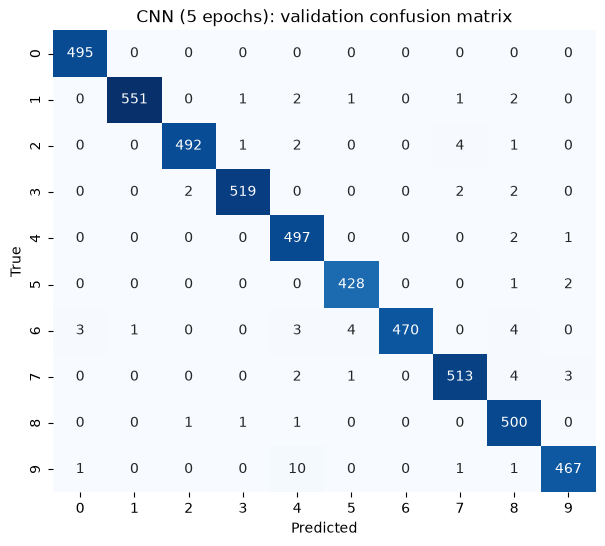

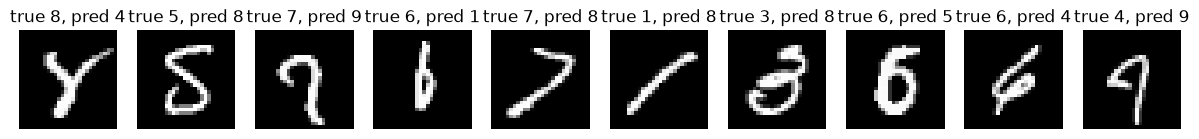

In [12]:
val_pred, y_val = predict(chosen, val_loader)

# Precision, recall and F1-score for each digit
print(classification_report(y_val, val_pred, digits=3))

# Rows = true digit, columns = predicted digit. The diagonal holds correct predictions;
# anything off the diagonal shows which digits get confused with each other.
cm = confusion_matrix(y_val, val_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"{chosen_result['model']}: validation confusion matrix")
plt.show()

# a few misclassified digits
val_data = val_loader.dataset
wrong = np.where(val_pred != y_val)[0][:10]
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for ax, i in zip(axes, wrong):
    ax.imshow(val_data[i][0].squeeze(), cmap="gray")
    ax.set_title(f"true {y_val[i]}, pred {val_pred[i]}")
    ax.axis("off")
plt.show()

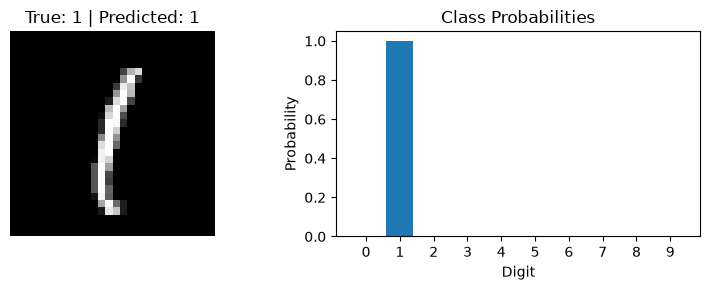

In [13]:
# Testing the model on a single image

def predict_single(model, dataset, index):
    model.eval()
    image, label = dataset[index]
    with torch.no_grad():
        output = model(image.unsqueeze(0).to(device))          # add batch dimension: [1, 1, 28, 28]
        probs = torch.softmax(output, dim=1).squeeze().cpu()   # logits -> probabilities that sum to 1
        predicted = probs.argmax().item()

    # Left: the image with its true and predicted label
    plt.figure(figsize=(8, 3))
    plt.subplot(1, 2, 1)
    plt.imshow(image.squeeze(), cmap='gray')
    plt.title(f"True: {label} | Predicted: {predicted}")
    plt.axis('off')

    # Right: how confident the model is in each digit
    plt.subplot(1, 2, 2)
    plt.bar(range(10), probs.numpy())
    plt.xticks(range(10))
    plt.title("Class Probabilities")
    plt.xlabel("Digit")
    plt.ylabel("Probability")
    plt.tight_layout()
    plt.show()

# Pick a random validation image
predict_single(chosen, val_loader.dataset, np.random.randint(len(val_loader.dataset)))